# Experiment readout: do retargeting ads cause visits and conversions?
Criteo Uplift v2.1, 5% random sample (699,009 users). Everything below is read from `reports/`, produced by `python -m abx.readout`. Metric design: `docs/metric_design.md`.

In [1]:
import json, pandas as pd
from IPython.display import Image, display
pd.set_option('display.float_format', lambda v: f'{v:,.5f}')
R = json.load(open('../reports/readout.json'))
full = json.load(open('../reports/full_dataset_stats.json'))

## 1. Health checks: can we trust the split?

In [2]:
srm = R['srm']
print(f"sample: {srm['n']:,} users, treated share {srm['observed_share']:.4f} vs designed 0.85, SRM p = {srm['p_value']:.3f}")
print(f"full dataset: {full['full_rows']:,} users, treated share {full['treat_share']:.4f}, control users exposed: {full['control_exposed']}")
print(f"balance: out-of-fold AUC predicting T from features = {R['balance_auc_t_from_features']:.4f}; "
      f"max |std mean diff| = {R['max_abs_std_mean_diff']:.3f} (one SE = {R['smd_se']:.4f})")
pd.DataFrame(R['rates_by_arm'])

sample: 699,009 users, treated share 0.8509 vs designed 0.85, SRM p = 0.036
full dataset: 13,979,592 users, treated share 0.8500, control users exposed: 0
balance: out-of-fold AUC predicting T from features = 0.5077; max |std mean diff| = 0.046 (one SE = 0.0034)


,visit,conversion,exposure
0,0.03870,0.00200,0.00000
1,0.04833,0.00312,0.03600


**Read:** the SRM p of 0.036 is a property of this random 5% sample. The full dataset is at 0.8500, and a p of 0.036 is far from the usual 0.001 alarm level, so this is **not an SRM**. Balance is the real finding: features predict assignment slightly but very significantly (AUC 0.508, mean differences up to 13 SEs). Criteo's erratum says feature distributions are advertiser-dependent and incrementality varied by advertiser. The likely cause is pooling of tests with different setups (a hypothesis; advertiser id is not in the data). **Consequence: the unadjusted difference in means is not trustworthy on its own. Adjust for features before reading the lift.**

## 2. Effect of assignment (ITT), with and without adjustment

In [3]:
itt = pd.read_csv('../reports/itt.csv')
itt['shift_vs_unadj_in_se'] = itt.groupby('outcome', group_keys=False).apply(
    lambda g: (g.estimate - g.estimate.iloc[0]) / g.se.iloc[0])
itt

/tmp/ipykernel_422/1098593818.py:2: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  itt['shift_vs_unadj_in_se'] = itt.groupby('outcome', group_keys=False).apply(


,outcome,estimator,estimate,se,ci_low,ci_high,p_value,rel_lift,variance_reduction,shift_vs_unadj_in_se
0,visit,unadjusted,0.00963,0.00066,0.00834,0.01092,0.00000,0.24890,0.00000,0.00000
1,visit,linear_features,0.00731,0.00059,0.00616,0.00847,0.00000,0.18903,0.20427,-3.51547
2,visit,cupac_lgbm,0.00628,0.00057,0.00516,0.00740,0.00000,0.16228,0.24392,-5.08612
3,visit,linear_plus_cupac,0.00672,0.00057,0.00560,0.00784,0.00000,0.17366,0.24957,-4.41837
4,visit,aipw_doubly_robust,0.00726,0.00060,0.00609,0.00843,0.00000,0.18772,0.17864,-3.59223
5,conversion,unadjusted,0.00112,0.00016,0.00081,0.00143,0.00000,0.56106,0.00000,0.00000
6,conversion,linear_features,0.00098,0.00015,0.00068,0.00128,0.00000,0.49134,0.02003,-0.89198
7,conversion,cupac_lgbm,0.00098,0.00015,0.00068,0.00128,0.00000,0.49136,0.01657,-0.89175
8,conversion,linear_plus_cupac,0.00097,0.00015,0.00066,0.00127,0.00000,0.48462,0.01984,-0.97800
9,conversion,aipw_doubly_robust,0.00084,0.00017,0.00050,0.00117,0.00000,0.41857,-0.21036,-1.82298


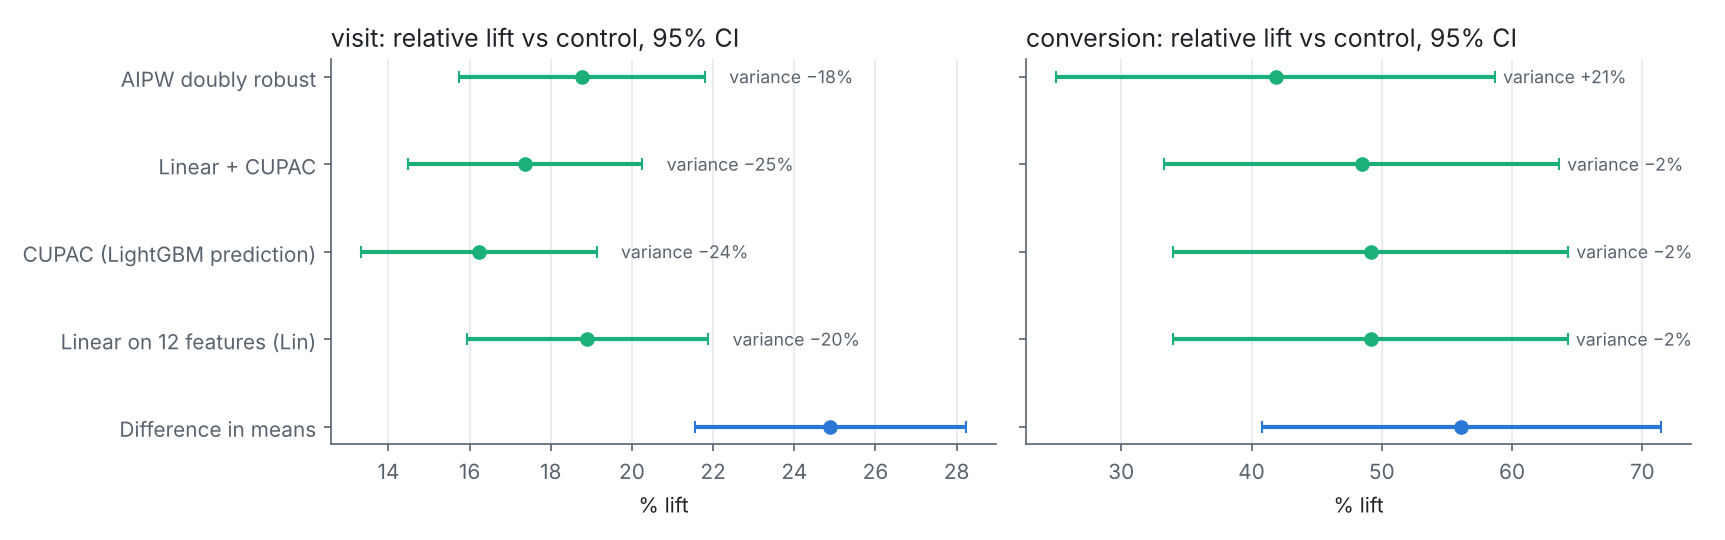

,visit,conversion
unadj_est,-0.00003,-0.00023
adj_est,-0.00045,-0.00030
shift_in_se,-0.59275,-0.35054
variance_reduction,0.33520,0.09092


In [4]:
display(Image('../reports/figures/effects-light.png'))
pd.DataFrame({y: R['itt'][y]['permuted_check'] for y in ['visit', 'conversion']})

**Read:** on a permuted A/A (clean randomization by construction), adjustment moves the estimate by under 1 SE, as it should. On the real assignment it moves the visit effect by about 4.4 SEs, which is imbalance correction, not noise. The adjusted estimators (Lin, CUPAC, AIPW) agree with each other, and adjustment cuts the variance of the visit estimate by 25% (2% for the rare conversion outcome).

## 3. Power

In [5]:
pd.read_csv('../reports/power.csv')

,outcome,sample,n,control_rate,mde_abs,mde_rel,mde_abs_adjusted,mde_rel_adjusted,var_reduction,n_adjusted
0,visit,this sample,699009,0.03870,0.00181,0.04689,0.00157,0.04062,0.24957,NaN
1,visit,full dataset,13979591,0.03870,0.00041,0.01049,0.00035,0.00908,0.24957,NaN
2,visit,n needed for 1% lift,15369013,0.03870,NaN,NaN,NaN,NaN,NaN,"11,533,400.00000"
3,visit,n needed for 2% lift,3842254,0.03870,NaN,NaN,NaN,NaN,NaN,"2,883,350.00000"
4,visit,n needed for 5% lift,614761,0.03870,NaN,NaN,NaN,NaN,NaN,"461,336.00000"
5,visit,n needed for 10% lift,153691,0.03870,NaN,NaN,NaN,NaN,NaN,"115,334.00000"
6,conversion,this sample,699009,0.00200,0.00042,0.21038,0.00042,0.20828,0.01984,NaN
7,conversion,full dataset,13979591,0.00200,0.00009,0.04704,0.00009,0.04657,0.01984,NaN
8,conversion,n needed for 1% lift,309372908,0.00200,NaN,NaN,NaN,NaN,NaN,"303,236,000.00000"
9,conversion,n needed for 2% lift,77343227,0.00200,NaN,NaN,NaN,NaN,NaN,"75,809,000.00000"


## 4. Peeking

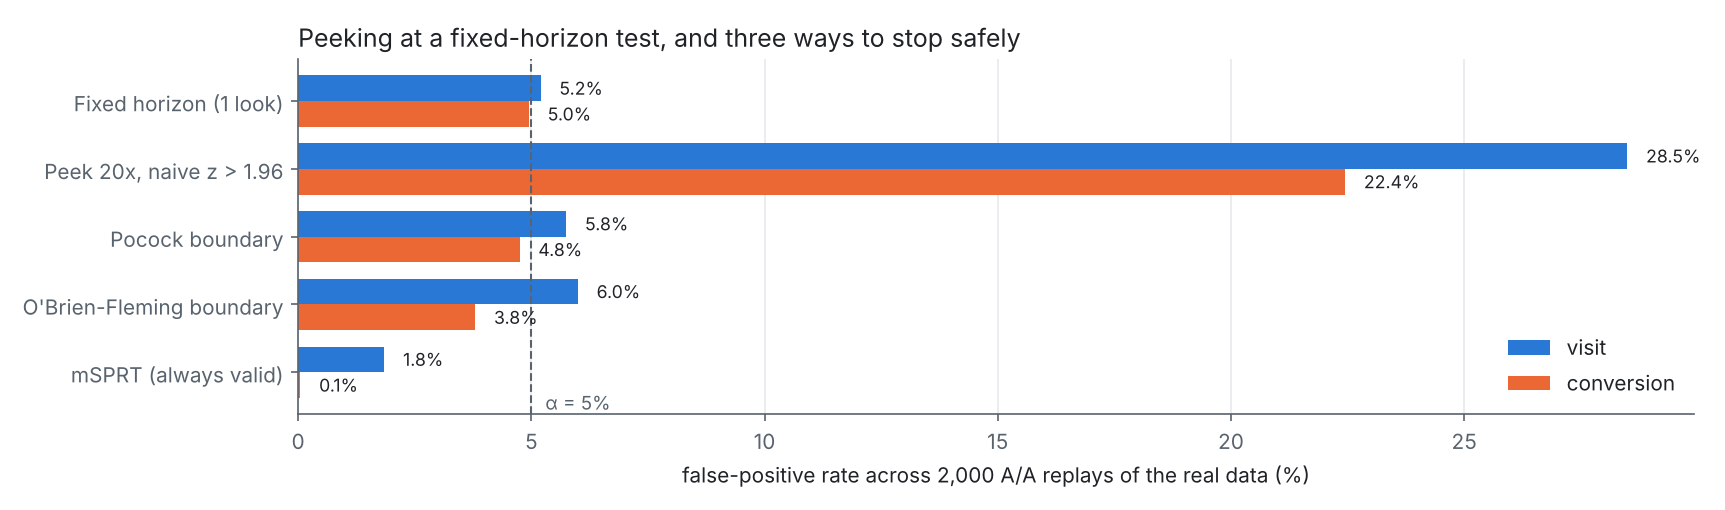

,K,reps,mode,tau2,pocock_c,obf_final_c,naive_reject_rate,naive_avg_stop_fraction,pocock_reject_rate,pocock_avg_stop_fraction,obrien_fleming_reject_rate,obrien_fleming_avg_stop_fraction,msprt_reject_rate,msprt_avg_stop_fraction,fixed_horizon_rate,outcome
0,20,2000,aa,0.00001,2.67207,2.12611,0.28500,0.34991,0.05750,0.38522,0.06000,0.78458,0.01850,0.47432,0.05200,visit
1,20,2000,bootstrap,0.00001,2.67207,2.12611,1.00000,0.05633,1.00000,0.06630,1.00000,0.17235,1.00000,0.09563,1.00000,visit
2,20,2000,aa,0.00000,2.67207,2.12611,0.22450,0.23719,0.04750,0.27790,0.03800,0.80395,0.00050,0.95000,0.04950,conversion
3,20,2000,bootstrap,0.00000,2.67207,2.12611,1.00000,0.11845,1.00000,0.17365,1.00000,0.33148,0.99850,0.46803,1.00000,conversion


In [6]:
display(Image('../reports/figures/peeking-light.png'))
pd.read_csv('../reports/peeking.csv')

**Read:** checking a fixed-horizon test 20 times and stopping at the first p < 0.05 gives false positives 5 to 6 times the nominal rate. Pocock and O'Brien-Fleming boundaries bring it back to about 5%. mSPRT is valid at any stopping time, so it is conservative with only 20 looks. On the real effect all methods reach 100% power, and the bootstrap `avg_stop_fraction` shows how early each would stop.

## 5. Effect on users who actually saw an ad (IV)

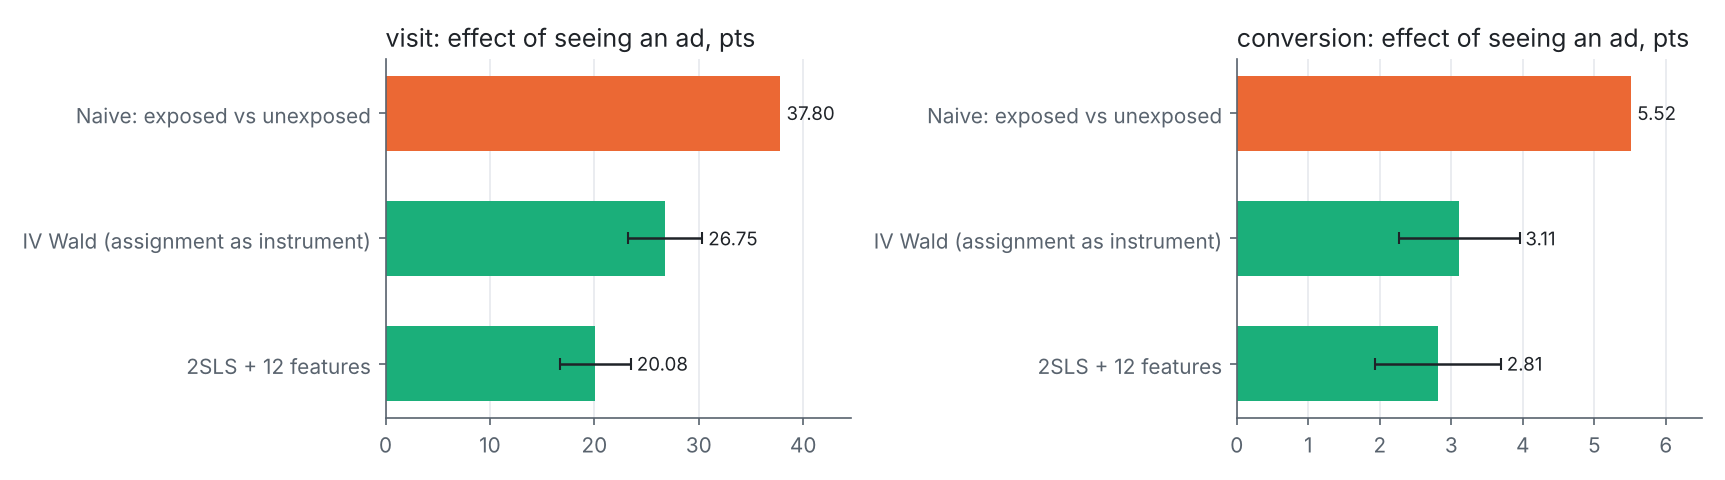

,visit,conversion
naive exposed-unexposed,0.37800,0.05520
IV Wald,0.26750,0.03110
IV 2SLS + features,0.20079,0.02812
naive / Wald,1.41308,1.77492
naive / 2SLS,1.88256,1.96306
first stage,0.03600,0.03600


In [7]:
display(Image('../reports/figures/iv-light.png'))
pd.DataFrame({y: {'naive exposed-unexposed': R['iv'][y]['naive']['exposed_vs_unexposed_all'],
                 'IV Wald': R['iv'][y]['wald']['late'], 'IV 2SLS + features': R['iv'][y]['tsls_with_features']['late'],
                 'naive / Wald': R['iv'][y]['naive']['exposed_vs_unexposed_all'] / R['iv'][y]['wald']['late'],
                 'naive / 2SLS': R['iv'][y]['naive']['exposed_vs_unexposed_all'] / R['iv'][y]['tsls_with_features']['late'],
                 'first stage': R['iv'][y]['wald']['itt_d']} for y in ['visit', 'conversion']})

## 6. Recommendation
**Ship (keep running ads for this audience), conditional on cost.** After adjusting for the feature imbalance, assignment to ads raises visits by about 0.7 percentage points (about +17 to 19%) and conversions by about 0.09 points (about +42 to 49%). Every adjusted 95% CI excludes zero. For users who actually see an ad, the effect is about 20 to 27 points on visits and about 3 points on conversions. Dashboards that compare exposed with unexposed users overstate this 1.4 to 2.0x, so bids priced from them would overpay.

**Before acting:** (1) get spend to compute cost per incremental conversion, the real ship criterion; (2) re-run with advertiser id or test id to stratify the imbalance away instead of modelling it; (3) treat the size of the conversion lift as uncertain. It is estimated on about 2,000 conversions in this sample.